# NN_L12_cost_accuracy

**Macro-F1 against measured milliseconds per sentence on a laptop for TF-IDF, prompted Qwen2.5 models and LLM embeddings with logistic regression, Financial PhraseBank test set.**

Neural Networks and Deep Learning (NN), Lecture 12 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L12/NN_L12_cost_accuracy/NN_L12_cost_accuracy.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

chain-of-thought 3B macro-F1 = 88.4   [cls.pb.cot_3B.f1]
zero-shot 0.5B macro-F1 = 31.0   [cls.pb.zs_05B.f1]


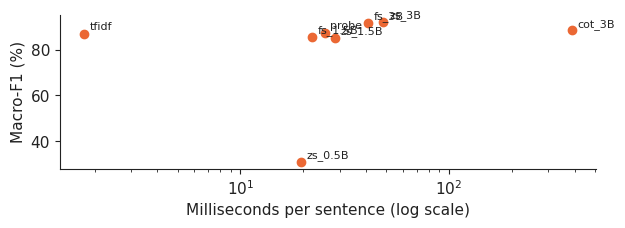

In [3]:
RES = REPO + 'lectures/L12/results/'
import json, urllib.request
def load_json(name):
    p = RES + name
    return json.load(open(p)) if os.path.exists(p) else json.load(urllib.request.urlopen(p))
from sklearn.metrics import f1_score, accuracy_score
LAB = {'pb': ['positive', 'negative', 'neutral'], 'tw': ['bullish', 'bearish', 'neutral']}
def f1(y, p, ds):
    return f1_score(y, p, labels=LAB[ds], average='macro')
def pred(df, m, ds):
    P = df[[f'{m}_{l}' for l in LAB[ds]]].values
    return [LAB[ds][i] for i in P.argmax(1)]
df = pd.read_csv(RES + 'predictions_pb.csv')
ms = {k.replace('05B', '0.5B').replace('15B', '1.5B'): v for k, v in load_json('lm_outputs.json')['ms_per_item']['pb'].items()}
M = ['tfidf', 'zs_0.5B', 'zs_1.5B', 'zs_3B', 'fs_1.5B', 'fs_3B', 'cot_3B', 'probe']
f = {m: 100 * f1(df.label, pred(df, m, 'pb'), 'pb') for m in M}
show('cls.pb.cot_3B.f1', 'chain-of-thought 3B macro-F1', round(f['cot_3B'], 1))
show('cls.pb.zs_05B.f1', 'zero-shot 0.5B macro-F1', round(f['zs_0.5B'], 1))
fig, ax = plt.subplots(figsize=(6.4, 2.4))
for m in M:
    ax.scatter(max(ms[m], 0.01), f[m], color=PAL['model'])
    ax.annotate(m, (max(ms[m], 0.01), f[m]), textcoords='offset points', xytext=(4, 3), fontsize=8)
ax.set_xscale('log')
ax.set_xlabel('Milliseconds per sentence (log scale)')
ax.set_ylabel('Macro-F1 (%)')
fig.tight_layout()
fig.savefig('cost_accuracy.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()